In [1]:
import numpy as np
import sympy as sm
import pandas as pd

import scipy as sp
from scipy.integrate import solve_ivp
import scipy.optimize as optimize

import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns

import os
from tqdm import tqdm
import glob

from scipy.stats import norm, skewnorm, gamma, lognorm, weibull_min, kstest

In [2]:
def dydt(t, y, par):

    par = np.abs(par)

    alpha = par[0]
    beta  = par[1]

    S = y[0]
    I = y[1]
    R = y[2]
    C = y[3]

    dS =  -beta*S*I
    dI = beta*S*I - alpha*I
    dR = alpha*I
    dC = beta*S*I

    return np.array([dS,dI,dR,dC])

# Solve the ODE model using solve_ivp


def SolveModel(par,tspan,init_cond,t_eval):

    ode_soln = solve_ivp(dydt,
                         tspan,
                         init_cond,
                         t_eval = t_eval,
                         args = (par,))
    return ode_soln

In [3]:
# Define initial conditions
N0 = 1000
I0 = 5
R0 = 0
C0 = 0
S0 = N0 - I0 - R0
init_cond = np.array([S0, I0, R0, C0])

#Define time variables
t_final=100
tspan = (1,t_final)
t_eval = np.arange(1, 101)  # instead of linspace or floats
tdata = np.arange(0,t_final)

In [4]:
params_df = pd.read_csv('../data/params_combos.csv')

In [5]:
params_df["R0"] = (params_df["Beta"] * 1000 / params_df["Alpha"]).round(2) #Calculate R0
params_df = params_df.sort_values("R0").reset_index(drop=True) #Sort df by R0

# Load trajectory files and map to params_df
data_dir = '../data/ctmc_trajectories' #Load data
csv_files = sorted(glob.glob(os.path.join(data_dir, '*.csv')))
param_to_file = {}
for file in csv_files:
    name = os.path.basename(file).replace('.csv', '').replace("alpha", "").replace("beta", "")
    parts = name.split("_")
    alpha = float(parts[0].replace("p", "."))
    beta = float(parts[1].replace("p", "."))
    param_to_file[(alpha, beta)] = file

In [6]:
# Store residual data
all_residuals = []

# Loop through all parameter sets
for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    par = (alpha, beta)

    # Load CTMC file
    file = param_to_file.get((alpha, beta))
    if file:
        df = pd.read_csv(file)

        # Solve the ODE at matching timepoints
        soln = SolveModel(par, tspan, init_cond, t_eval)
        I_ode = soln.y[1]
        I_peak = np.max(I_ode)
        dI_ode = np.gradient(I_ode, t_eval)
        t_peak = t_eval[np.argmax(I_ode)]

        for traj_id in df["trajectory"].unique():
            df_traj = df[df["trajectory"] == traj_id]
            df_traj = df_traj[df_traj["time"].isin(t_eval)].sort_values("time")

            for i, row_t in df_traj.iterrows():
                t = int(row_t["time"])
                t_idx = t - 1  # safe because t_eval = [1...100]

                i_ctmc = row_t["I"]
                i_ode_val = I_ode[t_idx]

                # Apply filtering threshold
                if i_ode_val >= 0.03 * I_peak and i_ctmc > 0: #Only calculate scaled residuals if the prevalence count is at least 5% of peak to avoid dividing by small numbers
                    residual = (i_ctmc - i_ode_val) / i_ode_val

                    all_residuals.append({
                        "time": t,
                        "I_ODE": i_ode_val,
                        "dI_dt": dI_ode[t_idx],
                        "residual": residual,
                        "R0": R0,
                        "alpha": alpha,
                        "beta": beta,
                        "trajectory": traj_id,
                        "time_from_peak": t - t_peak
                    })

# Convert to DataFrame
residuals_df = pd.DataFrame(all_residuals)

In [7]:
# Create phase column: before vs after peak
residuals_df["phase"] = np.where(residuals_df["time_from_peak"] < 0, "Before Peak", "After Peak")

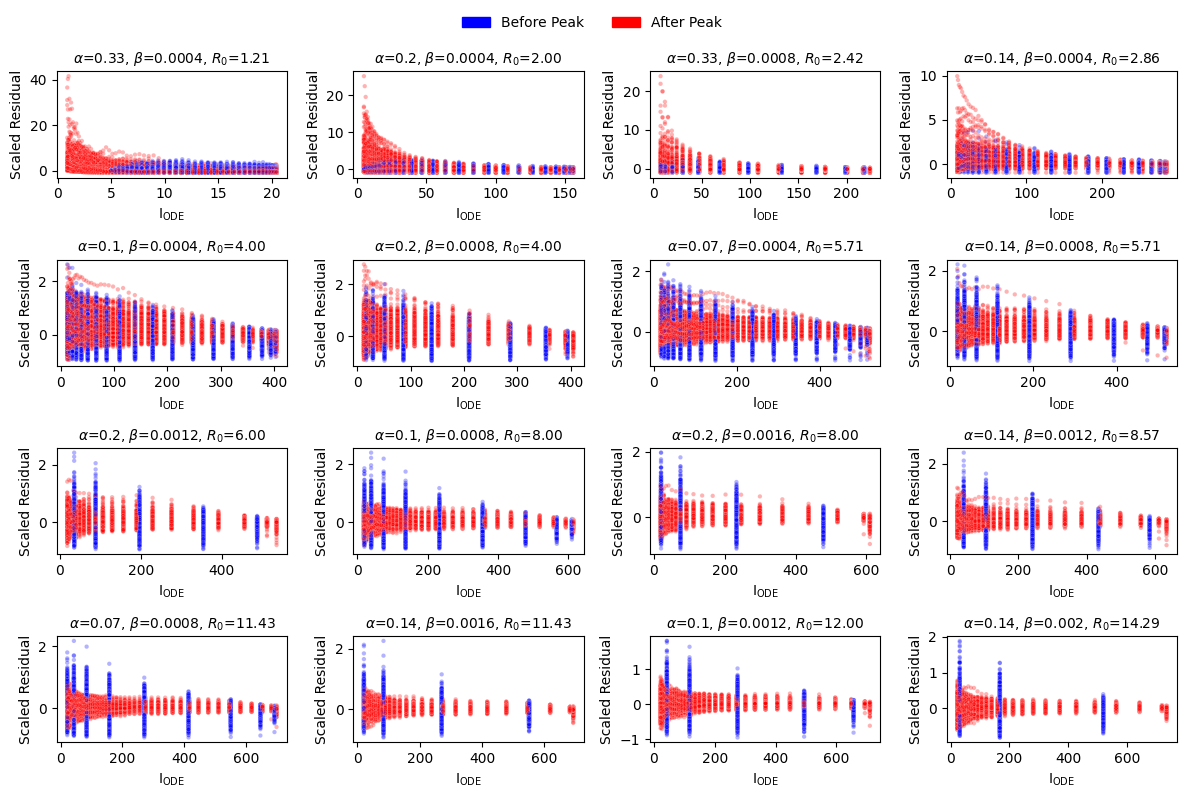

In [8]:
import matplotlib.patches as mpatches

# Add a column for shifted residuals (for positive-support distributions)
residuals_df["residual_shifted"] = residuals_df["residual"] + 1

# Set up 4x4 subplot grid
num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(12, 8))
axes = axes.flatten()

# Plot shifted residuals vs I_ODE
for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    subset = residuals_df[(residuals_df["alpha"] == alpha) & (residuals_df["beta"] == beta)]

    # sns.scatterplot(
    #     data=subset,
    #     x="I_ODE", y="residual_shifted", hue="phase",
    #     palette={"Before Peak": "blue", "After Peak": "red"},
    #     alpha=0.3, s=10, ax=ax, legend=False
    # )

    sns.scatterplot(
        data=subset,
        x="I_ODE", y="residual", hue="phase",
        palette={"Before Peak": "blue", "After Peak": "red"},
        alpha=0.3, s=10, ax=ax, legend=False
    )

    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}", fontsize = 10)
    ax.set_xlabel(r"${\mathrm{I_{ODE}}}$")
    ax.set_ylabel("Scaled Residual")

# Clean up unused axes
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

# Add custom legend
blue_patch = mpatches.Patch(color='blue', label='Before Peak')
red_patch = mpatches.Patch(color='red', label='After Peak')
fig.legend(
    handles=[blue_patch, red_patch],
    loc='upper center',
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=False,
)

#fig.suptitle("Shifted Scaled Residuals vs I_ODE", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

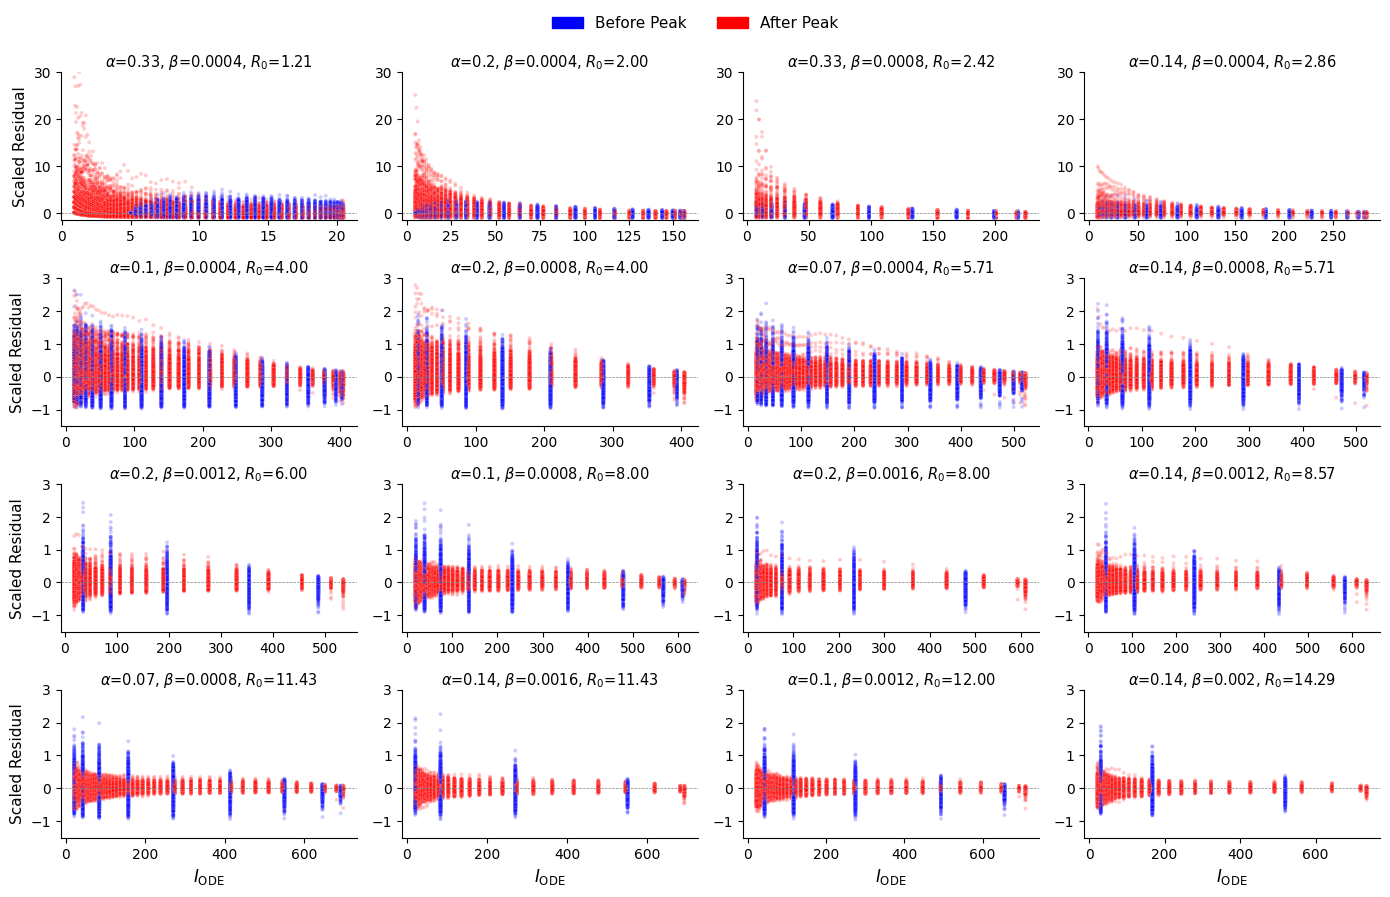

In [9]:
import matplotlib.patches as mpatches


# Sort params by R0 to show a smoother trend across subplots
params_df = params_df.sort_values("R0").reset_index(drop=True)

# Prepare figure
num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 9))
axes = axes.flatten()

# Plot residuals
for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    # Subset residuals
    subset = residuals_df[
        (residuals_df["alpha"] == alpha) &
        (residuals_df["beta"] == beta)
    ]

    # Scatter plot
    sns.scatterplot(
        data=subset,
        x="I_ODE", y="residual",
        hue="phase",
        palette={"Before Peak": "blue", "After Peak": "red"},
        alpha=0.2, s=8, ax=ax, legend=False
    )

    # Axis formatting
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}", fontsize=10.5, pad=1)

    # Show x-label only on bottom row
    if idx // num_cols == num_rows - 1:
        ax.set_xlabel(r"$I_{\mathrm{ODE}}$", fontsize = 12)
    else:
        ax.set_xlabel("")

    # Show y-label only on first column
    if idx % num_cols == 0:
        ax.set_ylabel("Scaled Residual", fontsize = 11)
    else:
        ax.set_ylabel("")

    # Optional: set consistent y limits
    if idx < 4:
        ax.set_ylim(-1.5, 30)
    else:
        ax.set_ylim(-1.5, 3)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Remove empty axes
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])



# Add shared legend
legend_patches = [
    mpatches.Patch(color='blue', label='Before Peak'),
    mpatches.Patch(color='red', label='After Peak')
]
fig.legend(
    handles=legend_patches,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=False, fontsize = 11
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


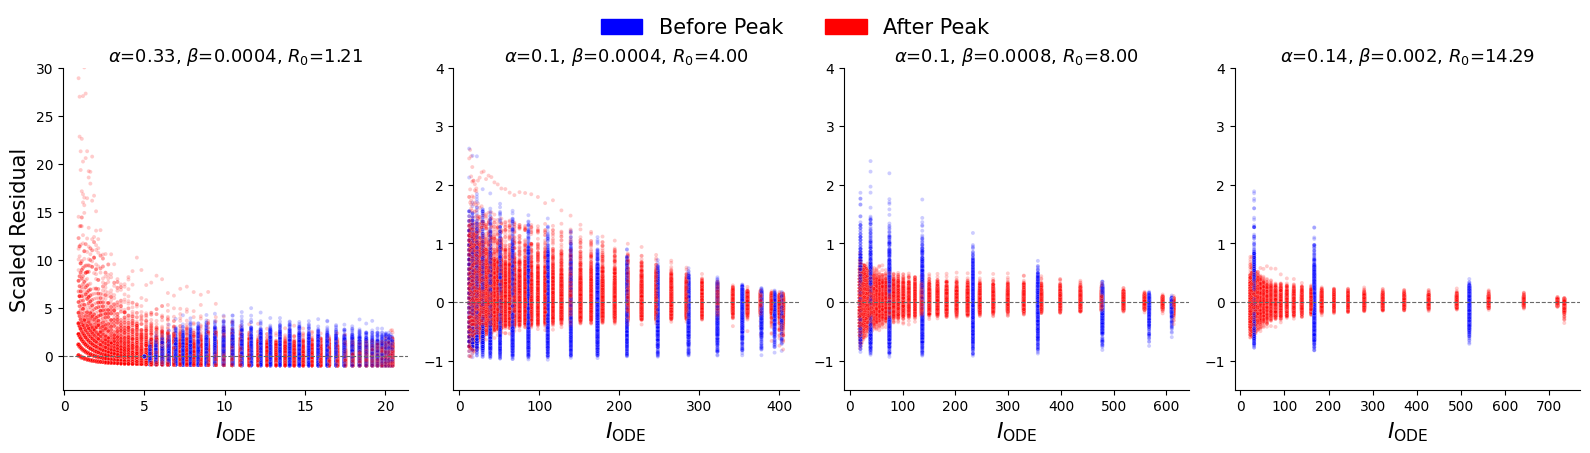

In [10]:
# Representative plots
import matplotlib.patches as mpatches

# Pick the four representative parameter sets (in this order)
selected_list = [
    {"Alpha": 0.33, "Beta": 0.0004},  # low R0 ~ 1.21 (skewed/heavy)
    {"Alpha": 0.10, "Beta": 0.0004},  # mid R0 = 4 (clear funnel)
    {"Alpha": 0.10, "Beta": 0.0008},  # higher R0 = 8 (more symmetric)
    {"Alpha": 0.14, "Beta": 0.002},   # very high R0 ~ 14.29 (tight spread)
]

# Keep only those rows (and in that order), bring along R0
selected_df = pd.DataFrame(selected_list)
selected_df = selected_df.merge(params_df[["Alpha","Beta","R0"]], on=["Alpha","Beta"], how="left")

# Prepare figure: 1 row x 4 cols
num_plots = len(selected_df)
num_cols = 4
num_rows = 1

fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, 4.5))
axes = np.atleast_1d(axes)

# Plot residuals
for idx, row in selected_df.reset_index(drop=True).iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    # Subset residuals
    subset = residuals_df[(residuals_df["alpha"] == alpha) & (residuals_df["beta"] == beta)]

    # Scatter plot (same aesthetics as before)
    sns.scatterplot(
        data=subset,
        x="I_ODE", y="residual",
        hue="phase",
        palette={"Before Peak": "blue", "After Peak": "red"},
        alpha=0.2, s=8, ax=ax, legend=False
    )

    # Axis formatting
    ax.axhline(0, color='dimgray', linewidth=0.8, linestyle='--')
    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}", fontsize=13, pad=1)

    # x/y labels
    ax.set_xlabel(r"$I_{\mathrm{ODE}}$", fontsize = 16)
    ax.set_ylabel("Scaled Residual" if idx == 0 else "", fontsize = 15)

    # Y-lims
    if idx == 0:
        ax.set_ylim(-3.5, 30)
    else:
        ax.set_ylim(-1.5, 4)

    # Clean spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Add shared legend
legend_patches = [
    mpatches.Patch(color='blue', label='Before Peak'),
    mpatches.Patch(color='red', label='After Peak'),
]
fig.legend(handles=legend_patches, loc='upper center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize = 15)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


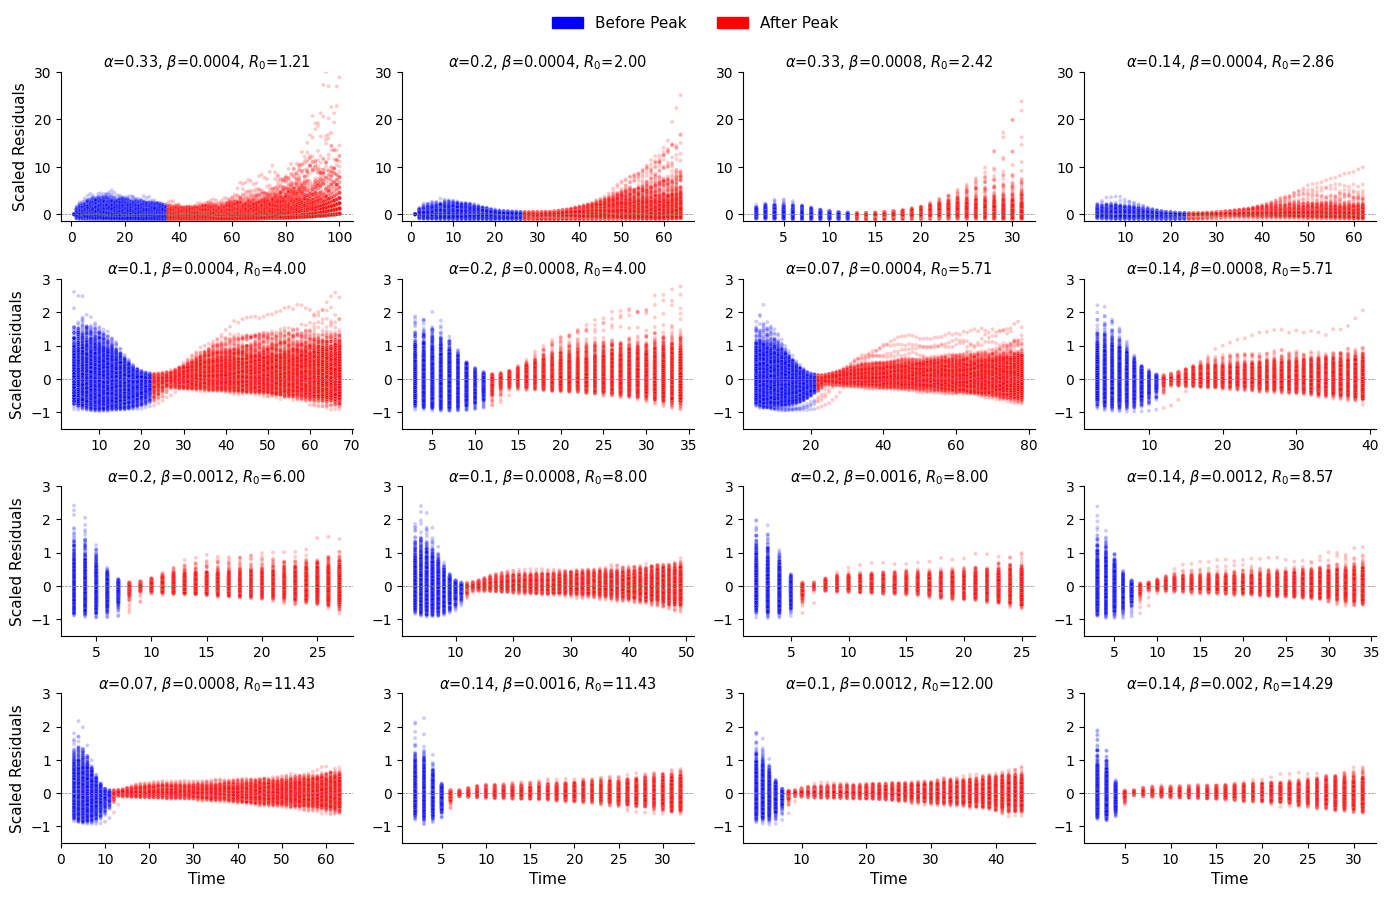

In [11]:
# Sort params by R0 to show a smoother trend across subplots
params_df = params_df.sort_values("R0").reset_index(drop=True)

# Prepare figure
num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 9))
axes = axes.flatten()

# Plot residuals
for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    # Subset residuals
    subset = residuals_df[
        (residuals_df["alpha"] == alpha) &
        (residuals_df["beta"] == beta)
    ]

    # Scatter plot (x-axis is now time)
    sns.scatterplot(
        data=subset,
        x="time", y="residual",
        hue="phase",
        palette={"Before Peak": "blue", "After Peak": "red"},
        alpha=0.2, s=8, ax=ax, legend=False
    )

    # Axis formatting
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--')
    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}", fontsize=10.5, pad=1)

    # Show x-label only on bottom row
    if idx // num_cols == num_rows - 1:
        ax.set_xlabel("Time", fontsize = 11)
    else:
        ax.set_xlabel("")

    # Show y-label only on first column
    if idx % num_cols == 0:
        ax.set_ylabel("Scaled Residuals", fontsize = 11)
    else:
        ax.set_ylabel("")

    # Optional: keep your y-limits logic
    if idx < 4:
        ax.set_ylim(-1.5, 30)
    else:
        ax.set_ylim(-1.5, 3)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Remove empty axes
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

# Add shared legend
legend_patches = [
    mpatches.Patch(color='blue', label='Before Peak'),
    mpatches.Patch(color='red', label='After Peak')
]
fig.legend(
    handles=legend_patches,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.0),
    ncol=2,
    frameon=False, fontsize = 11
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


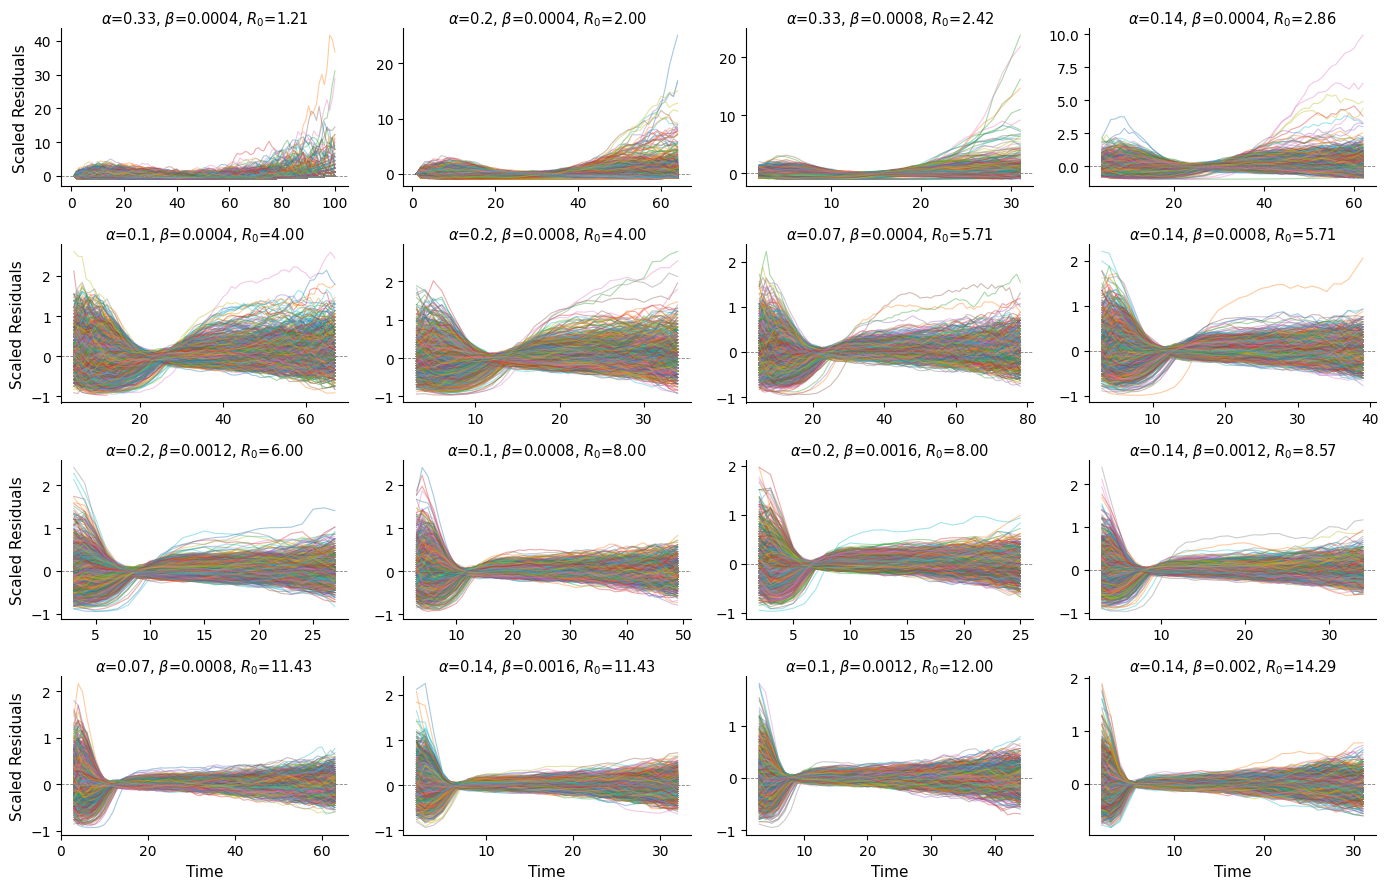

In [12]:
# Grid of spaghetti plots: one subplot per (alpha, beta) parameter set
# Assumes residuals_df has columns: time, residual, alpha, beta, trajectory, R0

# Sort params by R0 for smoother layout
params_df = params_df.sort_values("R0").reset_index(drop=True)

num_plots = len(params_df)   # e.g., 16
num_cols  = 4
num_rows  = int(np.ceil(num_plots / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 9), sharex=False, sharey=False)
axes = axes.flatten()

for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    # Filter to this parameter set
    subset = residuals_df[(residuals_df["alpha"] == alpha) & (residuals_df["beta"] == beta)]

    # Plot each CTMC trajectory residuals as a time series
    for traj_id, traj_data in subset.groupby("trajectory"):
        td = traj_data.sort_values("time")
        ax.plot(td["time"].values, td["residual"].values, linewidth=0.8, alpha=0.4)

    # Styling
    ax.axhline(0, color="gray", linewidth=0.6, linestyle="--")
    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}", fontsize=10.5, pad=1)

    # Labels only on left/bottom like your other grids
    if idx % num_cols == 0:
        ax.set_ylabel("Scaled Residuals", fontsize = 11)
    if idx // num_cols == num_rows - 1:
        ax.set_xlabel("Time", fontsize = 11)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Remove any extra axes (if num_plots not a multiple of num_cols)
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()



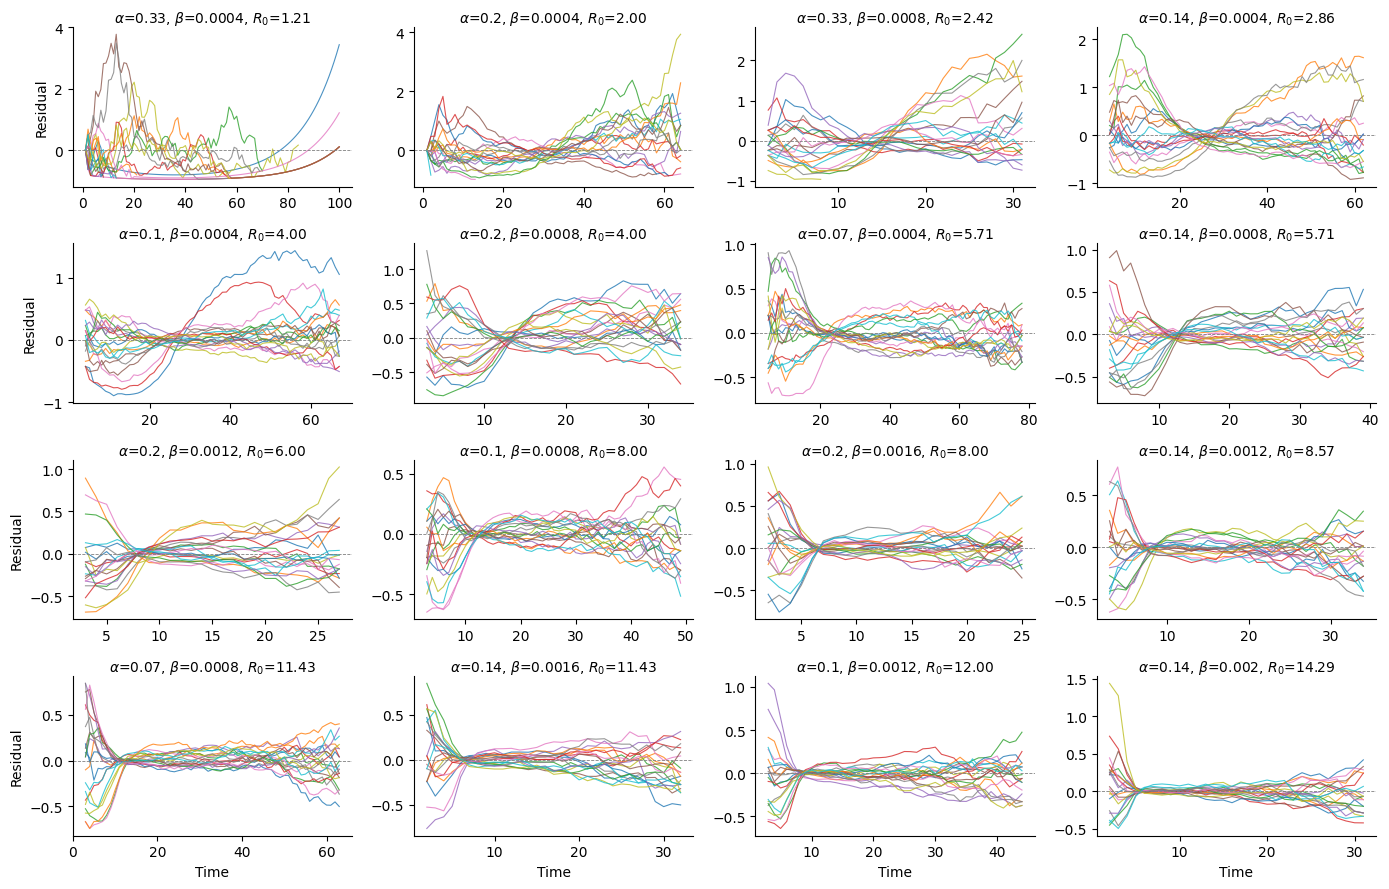

In [13]:
params_df = params_df.sort_values("R0").reset_index(drop=True)

num_plots = len(params_df)   # e.g., 16
num_cols  = 4
num_rows  = int(np.ceil(num_plots / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(14, 9), sharex=False, sharey=False)
axes = axes.flatten()

max_trajs = 20  # limit number of curves

for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    # Filter to this parameter set
    subset = residuals_df[(residuals_df["alpha"] == alpha) & (residuals_df["beta"] == beta)]

    # Randomly sample trajectories if more than max_trajs
    traj_ids = subset["trajectory"].unique()
    if len(traj_ids) > max_trajs:
        traj_ids = np.random.choice(traj_ids, size=max_trajs, replace=False)

    # Plot each chosen trajectory
    for traj_id in traj_ids:
        td = subset[subset["trajectory"] == traj_id].sort_values("time")
        ax.plot(td["time"].values, td["residual"].values, linewidth=0.8, alpha=0.8)

    # Styling
    ax.axhline(0, color="gray", linewidth=0.6, linestyle="--")
    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}", fontsize=10, pad=1)

    # Labels only on left/bottom like your other grids
    if idx % num_cols == 0:
        ax.set_ylabel("Residual")
    if idx // num_cols == num_rows - 1:
        ax.set_xlabel("Time")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Remove any extra axes (if num_plots not a multiple of num_cols)
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# AIC Test

In [14]:
from scipy.special import gammaln


# Reuse grouped shifted residuals
#residuals_df["residual_shifted"] = residuals_df["residual"] + 1
residuals_df["I_ODE_rounded"] = residuals_df["I_ODE"].round(2)
grouped = residuals_df.groupby(["alpha", "beta", "R0", "phase", "I_ODE_rounded"])

# Define distributions
distributions = {
    "norm": norm,
    "skewnorm": skewnorm,
    "gamma": gamma,
    "lognorm": lognorm,
    "weibull_min": weibull_min
}

# Function to calculate AIC: AIC = 2k - 2ln(L)
def compute_aic(log_likelihood, k):
    return 2 * k - 2 * log_likelihood

# Store AIC results
aic_results = []

# Fit loop
for (alpha, beta, R0, phase, I_val), group in tqdm(grouped, desc="Fitting AIC (shifted)"):
    data = group["residual_shifted"].values

    # Skip if data is too small or nearly constant
    if len(data) < 5 or np.std(data) < 1e-6:
        continue

    for name, dist in distributions.items():
        try:
            params = dist.fit(data)
            log_likelihood = np.sum(dist.logpdf(data, *params))
            k = len(params)
            aic = compute_aic(log_likelihood, k)

            aic_results.append({
                "alpha": alpha,
                "beta": beta,
                "R0": R0,
                "phase": phase,
                "I_ODE": I_val,
                "dist_name": name,
                "aic": aic,
                "log_likelihood": log_likelihood,
                "n_params": k,
                "n_obs": len(data)
            })
        except Exception:
            continue

# Store as DataFrame
aic_df_all_shifted = pd.DataFrame(aic_results)
aic_df_all_shifted.head()


Fitting AIC (shifted):   0%|          | 0/752 [00:00<?, ?it/s]

Fitting AIC (shifted):   1%|          | 4/752 [00:00<00:21, 34.85it/s]

Fitting AIC (shifted):   1%|▏         | 11/752 [00:00<00:15, 48.01it/s]

Fitting AIC (shifted):   2%|▏         | 16/752 [00:00<00:15, 47.95it/s]

Fitting AIC (shifted):   3%|▎         | 21/752 [00:00<00:17, 41.83it/s]

Fitting AIC (shifted):   3%|▎         | 26/752 [00:00<00:18, 39.71it/s]

... (146 outputs left out)

Fitting AIC (shifted):  99%|█████████▉| 746/752 [00:19<00:00, 38.41it/s]

Fitting AIC (shifted): 100%|█████████▉| 751/752 [00:19<00:00, 39.55it/s]

Fitting AIC (shifted): 100%|██████████| 752/752 [00:19<00:00, 38.48it/s]

,alpha,beta,R0,phase,I_ODE,dist_name,aic,log_likelihood,n_params,n_obs
0,0.07,0.0004,5.71,After Peak,16.49,norm,420.257897,-208.128949,2,1000
1,0.07,0.0004,5.71,After Peak,16.49,skewnorm,372.442945,-183.221472,3,1000
2,0.07,0.0004,5.71,After Peak,16.49,gamma,369.826942,-181.913471,3,1000
3,0.07,0.0004,5.71,After Peak,16.49,lognorm,368.374332,-181.187166,3,1000
4,0.07,0.0004,5.71,After Peak,16.49,weibull_min,inf,-inf,3,1000


/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/556775561.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=best_dist_counts, x="Distribution", y="Percent", palette="pastel")


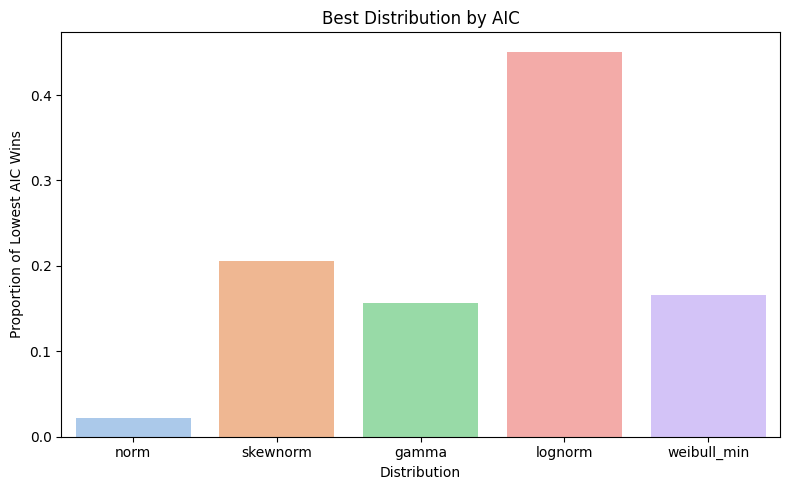

In [15]:
# Find the best (lowest AIC) distribution for each group
best_aic_df = (
    aic_df_all_shifted
    .sort_values("aic")
    .groupby(["alpha", "beta", "I_ODE"])  # no phase split for now
    .first()
    .reset_index()
)

# Count how many times each distribution is best
best_dist_counts = best_aic_df["dist_name"].value_counts().reindex(
    ["norm", "skewnorm", "gamma", "lognorm", "weibull_min"]
).fillna(0).reset_index()
best_dist_counts.columns = ["Distribution", "Count"]

# Convert counts to percentages
best_dist_counts["Percent"] = best_dist_counts["Count"] / best_dist_counts["Count"].sum()

# Plot percentage instead of raw counts
plt.figure(figsize=(8, 5))
sns.barplot(data=best_dist_counts, x="Distribution", y="Percent", palette="pastel")
plt.title("Best Distribution by AIC")
plt.xlabel("Distribution")
plt.ylabel("Proportion of Lowest AIC Wins")
plt.tight_layout()
plt.show()


# # Plot
# plt.figure(figsize=(8, 5))
# sns.barplot(data=best_dist_counts, x="Distribution", y="Count", palette="pastel")
# plt.title("Best Distribution by AIC ")
# plt.xlabel("Distribution")
# plt.ylabel("Number of Lowest AIC Wins")
# plt.tight_layout()
# plt.show()


/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/815593205.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["R0_bin", "dist_name"])
/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/815593205.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  best_counts_r0["proportion"] = best_counts_r0.groupby("R0_bin")["count"].transform(lambda x: x / x.sum())


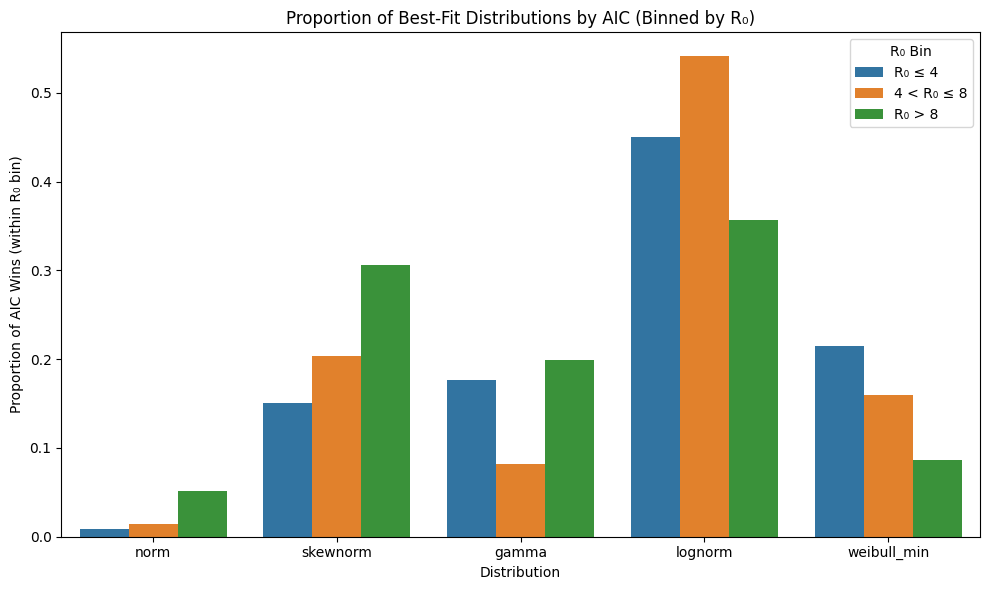

In [16]:
# Bin R0 into categories
aic_df_all_shifted["R0_bin"] = pd.cut(
    aic_df_all_shifted["R0"],
    bins=[0, 4, 8, 15],
    labels=["R₀ ≤ 4", "4 < R₀ ≤ 8", "R₀ > 8"]
)

# Find best (lowest AIC) for each group (still ignoring phase for now)
best_aic_df_r0 = (
    aic_df_all_shifted
    .sort_values("aic")
    .groupby(["alpha", "beta", "I_ODE"])
    .first()
    .reset_index()
)

# Count how many times each distribution is best in each R₀ bin
best_counts_r0 = (
    best_aic_df_r0
    .groupby(["R0_bin", "dist_name"])
    .size()
    .reset_index(name="count")
)

# Normalize within each R₀ bin
best_counts_r0["proportion"] = best_counts_r0.groupby("R0_bin")["count"].transform(lambda x: x / x.sum())

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=best_counts_r0,
    x="dist_name", y="proportion", hue="R0_bin",
    order=["norm", "skewnorm", "gamma", "lognorm", "weibull_min"]
)
plt.title("Proportion of Best-Fit Distributions by AIC (Binned by R₀)")
plt.xlabel("Distribution")
plt.ylabel("Proportion of AIC Wins (within R₀ bin)")
plt.legend(title="R₀ Bin")
plt.tight_layout()
plt.show()

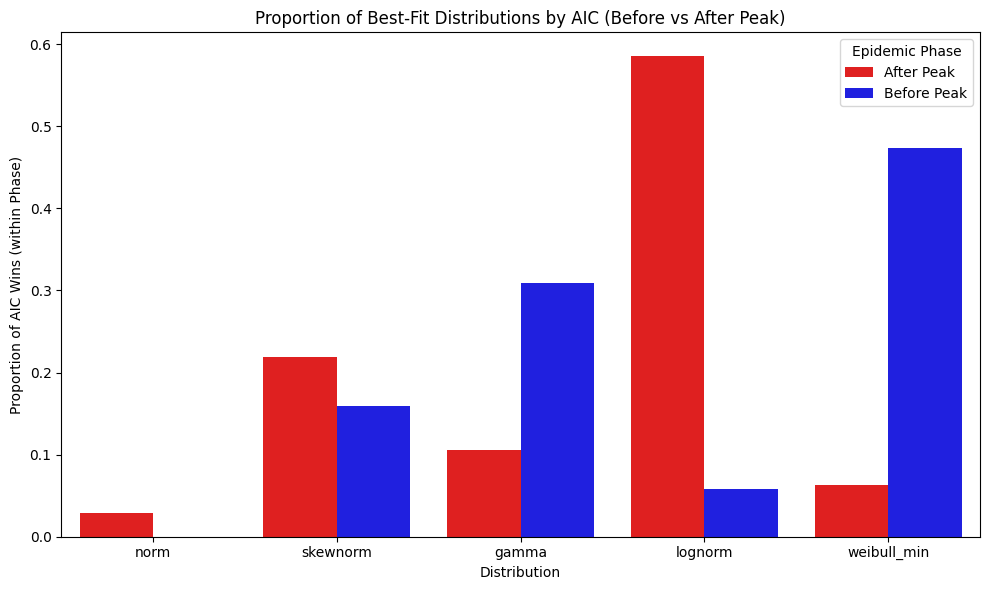

In [17]:
# Find best distribution (lowest AIC) by full group including phase
best_aic_df_phase = (
    aic_df_all_shifted
    .sort_values("aic")
    .groupby(["alpha", "beta", "I_ODE", "phase"])
    .first()
    .reset_index()
)

# Count how many times each distribution is best by phase
best_counts_phase = (
    best_aic_df_phase
    .groupby(["phase", "dist_name"])
    .size()
    .reset_index(name="count")
)

# Normalize within each phase
best_counts_phase["proportion"] = best_counts_phase.groupby("phase")["count"].transform(lambda x: x / x.sum())

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(
    data=best_counts_phase,
    x="dist_name", y="proportion", hue="phase",
    order=["norm", "skewnorm", "gamma", "lognorm", "weibull_min"],
    palette={"Before Peak": "blue", "After Peak": "red"}
)
plt.title("Proportion of Best-Fit Distributions by AIC (Before vs After Peak)")
plt.xlabel("Distribution")
plt.ylabel("Proportion of AIC Wins (within Phase)")
plt.legend(title="Epidemic Phase")
plt.tight_layout()
plt.show()

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/2387437867.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([lbl if lbl != "weibull_min" else "weibull" for lbl in axes[1].get_xticklabels()], fontsize = 12)


/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/2387437867.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels([lbl if lbl != "weibull_min" else "weibull" for lbl in axes[2].get_xticklabels()], fontsize = 12)


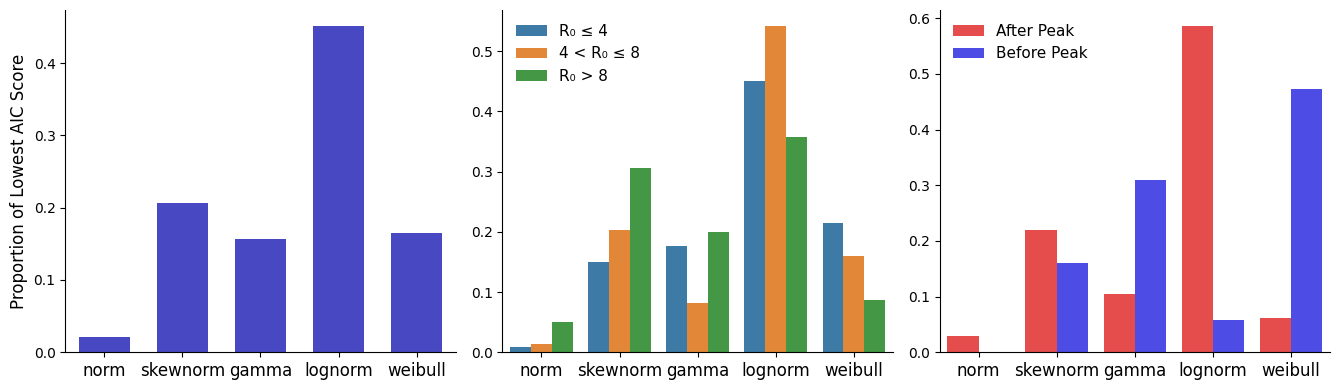

In [18]:
# Set up 1x3 subplot
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))

# First subplot: Overall best distribution
sns.barplot(
    data=best_dist_counts, x="Distribution", y="Percent", ax=axes[0], color = 'mediumblue', alpha = 0.8, width = 0.65
)

labels = [label.get_text().replace("weibull_min", "weibull") for label in axes[0].get_xticklabels()]
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels(labels, fontsize = 12)

#axes[0].set_title("Best Distribution by AIC")
axes[0].set_ylabel("Proportion of Lowest AIC Score", fontsize = 12)
axes[0].set_xlabel("")
axes[0].spines['right'].set_visible(False)
axes[0].spines['top'].set_visible(False)


# Second subplot: By R₀ bin
sns.barplot(
    data=best_counts_r0,
    x="dist_name", y="proportion", hue="R0_bin",
    order=["norm", "skewnorm", "gamma", "lognorm", "weibull_min"],alpha= 0.95,
    ax=axes[1]
)
axes[1].set_xticklabels([lbl if lbl != "weibull_min" else "weibull" for lbl in axes[1].get_xticklabels()], fontsize = 12)

labels = [label.get_text().replace("weibull_min", "weibull") for label in axes[1].get_xticklabels()]
axes[1].set_xticks(axes[1].get_xticks())
axes[1].set_xticklabels(labels)


#axes[1].set_title("Best-Fit Distributions by AIC (Binned by $R_0$)")
axes[1].set_ylabel("")
axes[1].set_xlabel("")
axes[1].legend(frameon=False, fontsize = 11)
axes[1].spines['right'].set_visible(False)
axes[1].spines['top'].set_visible(False)

# Third subplot: By epidemic phase
sns.barplot(
    data=best_counts_phase,
    x="dist_name", y="proportion", hue="phase",
    order=["norm", "skewnorm", "gamma", "lognorm", "weibull_min"],
    palette={"Before Peak": "blue", "After Peak": "red"}, alpha= 0.8,
    ax=axes[2]
)
axes[2].set_xticklabels([lbl if lbl != "weibull_min" else "weibull" for lbl in axes[2].get_xticklabels()], fontsize = 12)

labels = [label.get_text().replace("weibull_min", "weibull") for label in axes[2].get_xticklabels()]
axes[2].set_xticks(axes[2].get_xticks())
axes[2].set_xticklabels(labels)

#axes[2].set_title("Best-Fit Distributions by AIC (Before vs After Peak)")
axes[2].set_ylabel("")
axes[2].set_xlabel("")
axes[2].legend(frameon=False, fontsize = 11)
axes[2].spines['right'].set_visible(False)
axes[2].spines['top'].set_visible(False)

plt.tight_layout()
plt.show()


# Anderson–Darling test

In [19]:
# Function to compute the Stephens-corrected Anderson–Darling statistic
def compute_stephens_AD(log_data):
    n = len(log_data)
    sorted_data = np.sort(log_data)
    mu_hat = np.mean(log_data)
    sigma_hat = np.std(log_data, ddof=1)
    cdf_vals = norm.cdf(sorted_data, loc=mu_hat, scale=sigma_hat)

    i = np.arange(1, n + 1)
    A2 = -n - np.sum((2*i - 1) / n * (np.log(cdf_vals) + np.log(1 - cdf_vals[::-1])))
    A2_star = A2 * (1 + 0.75/n + 2.25/(n**2))
    return A2_star

# Storage for A–D results
ad_results = []

# Loop through the grouped residuals
for (alpha, beta, R0, phase, I_val), group in tqdm(grouped, desc="Computing A–D stats"):
    data = group["residual_shifted"].values

    # Ensure sufficient data points
    if len(data) >= 8:
        # Step 1: Log-transform the shifted residuals
        log_data = np.log(data)

        # Step 2: Compute the Stephens-corrected A–D statistic
        A2_star = compute_stephens_AD(log_data)

        # Step 3: Store results
        ad_results.append({
            "alpha": alpha,
            "beta": beta,
            "R0": R0,
            "phase": phase,
            "I_ODE": I_val,
            "n_obs": len(log_data),
            "A2_star": A2_star
        })

# Convert to DataFrame for further analysis
ad_df = pd.DataFrame(ad_results)


Computing A–D stats:   0%|          | 0/752 [00:00<?, ?it/s]

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/scipy/stats/_distn_infrastructure.py:2129: RuntimeWarning: invalid value encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
Computing A–D stats: 100%|██████████| 752/752 [00:00<00:00, 8845.99it/s]

In [20]:
ad_df

,alpha,beta,R0,phase,I_ODE,n_obs,A2_star
0,0.07,0.0004,5.71,After Peak,16.49,1000,4.210366
1,0.07,0.0004,5.71,After Peak,17.65,1000,4.166141
2,0.07,0.0004,5.71,After Peak,18.89,1000,3.383450
3,0.07,0.0004,5.71,After Peak,20.22,1000,3.038230
4,0.07,0.0004,5.71,After Peak,21.65,1000,2.401366
...,...,...,...,...,...,...,...
747,0.33,0.0008,2.42,Before Peak,98.27,991,33.931089
748,0.33,0.0008,2.42,Before Peak,133.02,990,44.634900
749,0.33,0.0008,2.42,Before Peak,168.82,990,62.798538
750,0.33,0.0008,2.42,Before Peak,198.86,990,88.448686


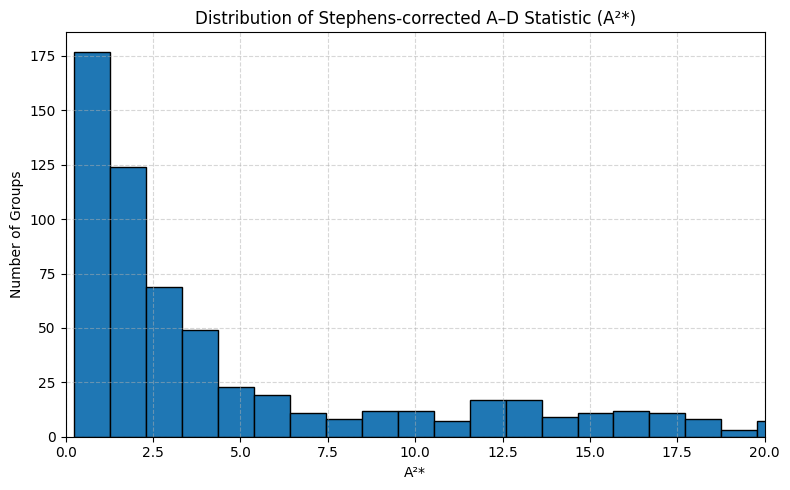

In [21]:
plt.figure(figsize=(8, 5))
plt.hist(ad_df["A2_star"], bins=150, edgecolor="black")
plt.title("Distribution of Stephens-corrected A–D Statistic (A²*)")
plt.xlabel("A²*")
plt.ylabel("Number of Groups")
plt.xlim(0,20)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [22]:
# Define the critical values in ascending order of significance level
critical_values = [
    (0.15, 0.576),
    (0.10, 0.656),
    (0.05, 0.787),
    (0.025, 0.918),
    (0.01, 1.092)
]


# Convert your critical values to a DataFrame
critical_df = pd.DataFrame(critical_values, columns=["alpha", "critical_value"])

# Create a wide-format rejection table (each column = one alpha level)
for alpha, crit_val in critical_values:
    ad_df[f"reject_{alpha}"] = ad_df["A2_star"] > crit_val

# Melt to long format for easy grouping
rejection_long = ad_df.melt(
    id_vars=["phase"],
    value_vars=[f"reject_{alpha}" for alpha, _ in critical_values],
    var_name="alpha",
    value_name="rejected"
)

# Clean up alpha labels (from 'reject_0.05' to '0.05')
rejection_long["alpha"] = rejection_long["alpha"].str.replace("reject_", "").astype(float)

# Compute rejection rate by alpha level and phase
rejection_summary = (
    rejection_long
    .groupby(["alpha", "phase"])["rejected"]
    .mean()
    .reset_index()
)



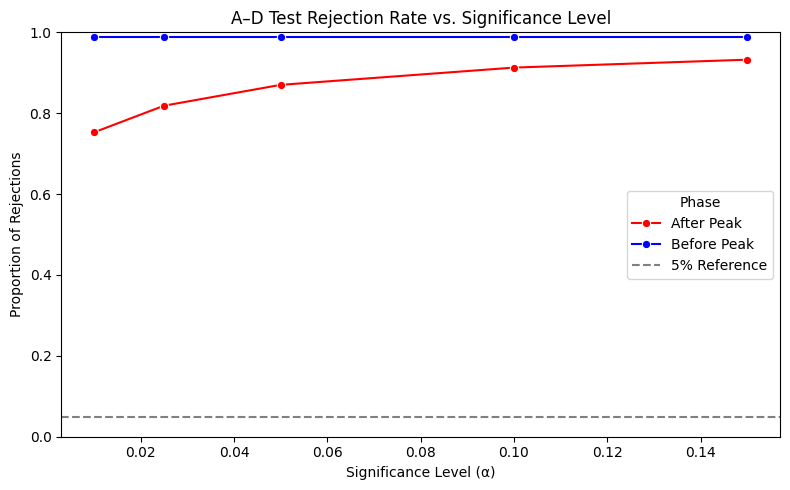

In [23]:
plt.figure(figsize=(8, 5))
sns.lineplot(data=rejection_summary, x="alpha", y="rejected", hue="phase", marker="o",
             palette={"Before Peak": "blue", "After Peak": "red"})

plt.axhline(y=0.05, linestyle="--", color="gray", label="5% Reference")
plt.xlabel("Significance Level (α)")
plt.ylabel("Proportion of Rejections")
plt.title("A–D Test Rejection Rate vs. Significance Level")
plt.ylim(0, 1)
plt.legend(title="Phase")
plt.tight_layout()
plt.show()


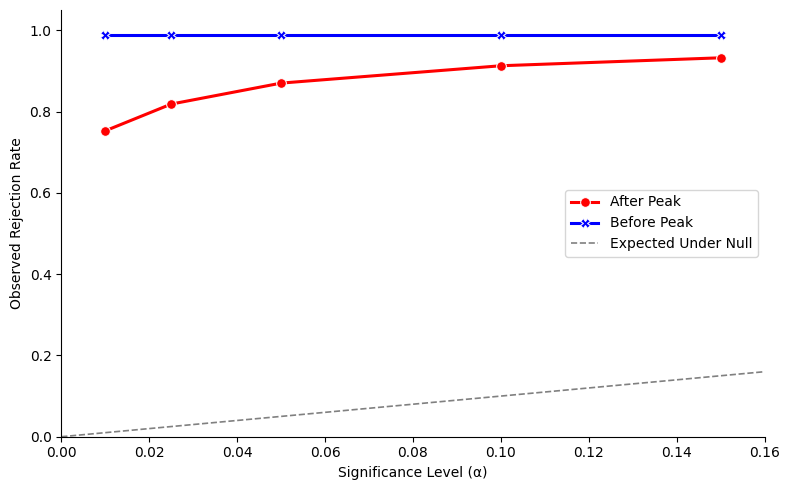

In [24]:
plt.figure(figsize=(8, 5))
sns.lineplot(
    data=rejection_summary,
    x="alpha", y="rejected", hue="phase",
    style="phase", markers=True, dashes=False,
    palette={"Before Peak": "blue", "After Peak": "red"},
    linewidth=2.2, markersize=7
)

# Diagonal reference line
plt.plot([0, 0.16], [0, 0.16], linestyle="--", color="gray", linewidth=1.2, label="Expected Under Null")

# Axes and formatting
plt.xlabel("Significance Level (α)")
plt.ylabel("Observed Rejection Rate")
#plt.title("A–D Test Rejection Rate vs. Significance Level")
plt.ylim(0, 1.05)
plt.xlim(0, 0.16)
plt.legend(loc="center right")  # Adjusted to mid-right
# Remove top and right spines
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Optionally remove gridlines
ax.grid(False)

plt.tight_layout()
plt.show()


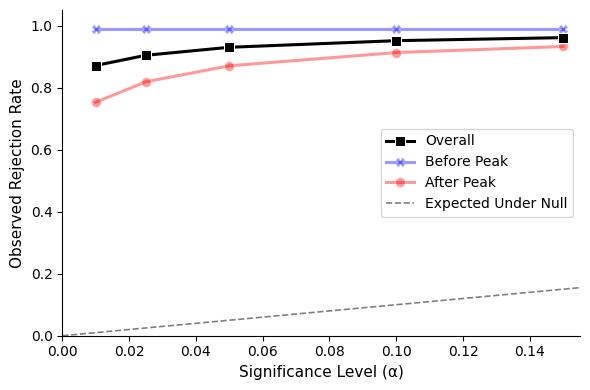

In [25]:
# Add combined line to rejection_summary
combined_summary = (
    rejection_summary
    .groupby("alpha")["rejected"]
    .mean()
    .reset_index()
    .assign(phase="Combined")
)
full_summary = pd.concat([rejection_summary, combined_summary], ignore_index=True)

plt.figure(figsize=(6, 4))
sns.lineplot(
    data=rejection_summary,
    x="alpha", y="rejected", hue="phase",
    style="phase", markers=True, dashes=False,
    palette={"Before Peak": "blue", "After Peak": "red"},
    linewidth=2.2, markersize=7, alpha = 0.4
)

sns.lineplot(
    data=full_summary[full_summary["phase"] == "Combined"],
    x="alpha", y="rejected", label="Overall",
    marker="s", linewidth=2.2, markersize=7, color="black"
)

# Diagonal reference line
plt.plot([0, 0.16], [0, 0.16], linestyle="--", color="gray", linewidth=1.2, label="Expected Under Null")

# Axes and formatting
plt.xlabel("Significance Level (α)", fontsize = 11)
plt.ylabel("Observed Rejection Rate", fontsize = 11)
plt.ylim(0, 1.05)
plt.xlim(0, 0.155)
plt.legend(loc="center right")

# Remove top and right spines
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(False)

#REorder legend
handles, labels = ax.get_legend_handles_labels()
order = ["Overall", "Before Peak", "After Peak", "Expected Under Null"]
ordered_handles = [handles[labels.index(lab)] for lab in order if lab in labels]
ordered_labels = [lab for lab in order if lab in labels]
ax.legend(ordered_handles, ordered_labels, loc="center right")


plt.tight_layout()
plt.show()


In [26]:
# Function to determine the rejection level
def get_rejection_level(a2_star):
    for level, crit_val in critical_values:
        if a2_star <= crit_val:
            return f"p > {level}"
    return "p < 0.01"

# Apply the function to your DataFrame
ad_df["rejection_level"] = ad_df["A2_star"].apply(get_rejection_level)


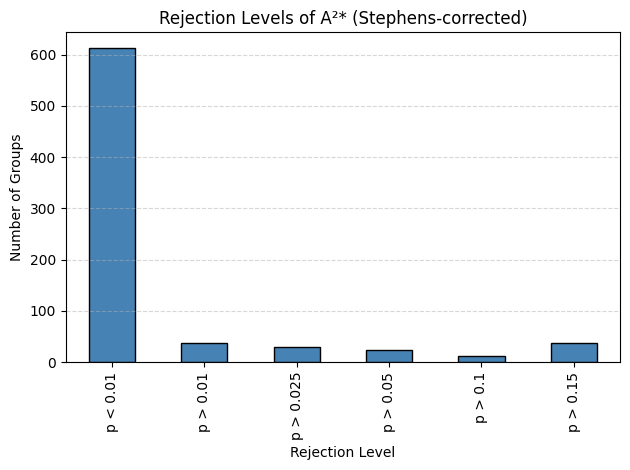

In [27]:
ad_df["rejection_level"].value_counts().sort_index().plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Rejection Levels of A²* (Stephens-corrected)")
plt.xlabel("Rejection Level")
plt.ylabel("Number of Groups")
plt.grid(True, axis='y', linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/758228692.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ad_df, x="phase", y="A2_star", palette={"Before Peak": "blue", "After Peak": "red"})


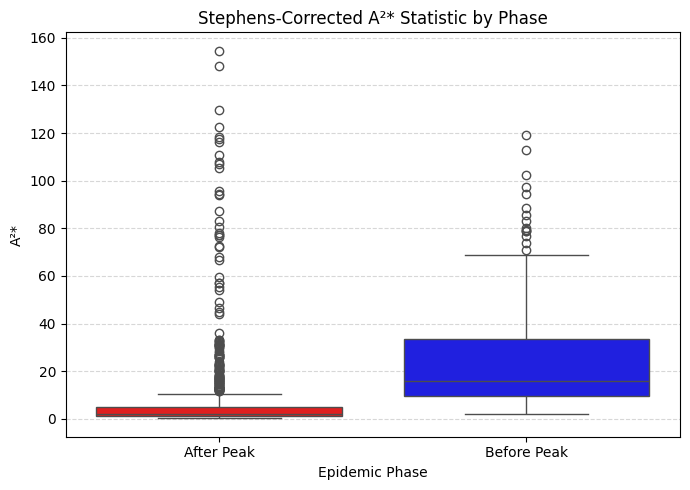

In [28]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=ad_df, x="phase", y="A2_star", palette={"Before Peak": "blue", "After Peak": "red"})
plt.title("Stephens-Corrected A²* Statistic by Phase")
plt.xlabel("Epidemic Phase")
plt.ylabel("A²*")
plt.grid(True, axis='y', linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


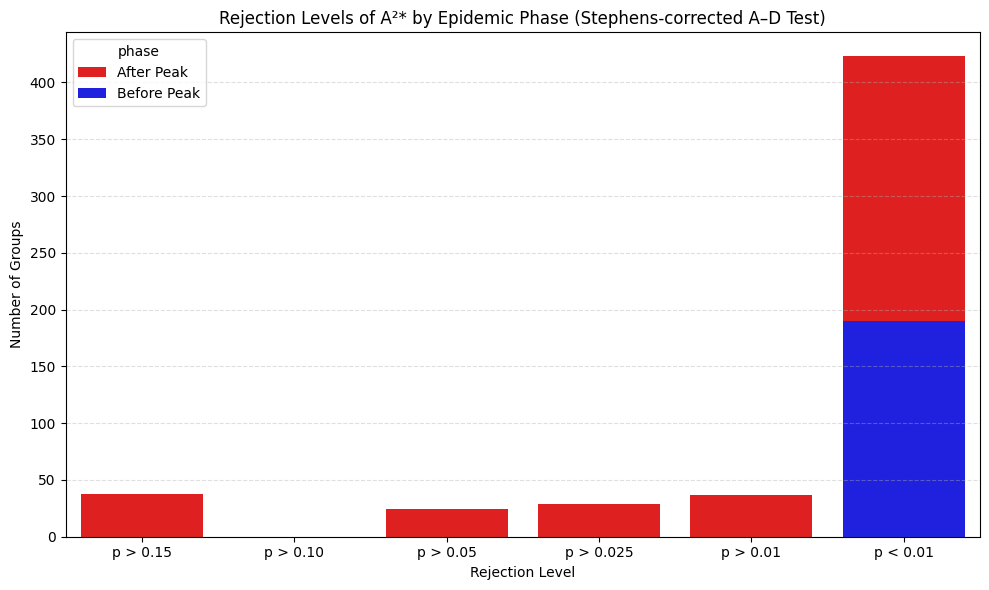

In [29]:
# Ensure rejection_level is ordered
rejection_order = ["p > 0.15", "p > 0.10", "p > 0.05", "p > 0.025", "p > 0.01", "p < 0.01"]
ad_df["rejection_level"] = pd.Categorical(ad_df["rejection_level"], categories=rejection_order, ordered=True)

plt.figure(figsize=(10, 6))
sns.countplot(data=ad_df, x="rejection_level", hue="phase", palette={"Before Peak": "blue", "After Peak": "red"})
plt.title("Rejection Levels of A²* by Epidemic Phase (Stephens-corrected A–D Test)")
plt.xlabel("Rejection Level")
plt.ylabel("Number of Groups")
plt.grid(True, axis='y', linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


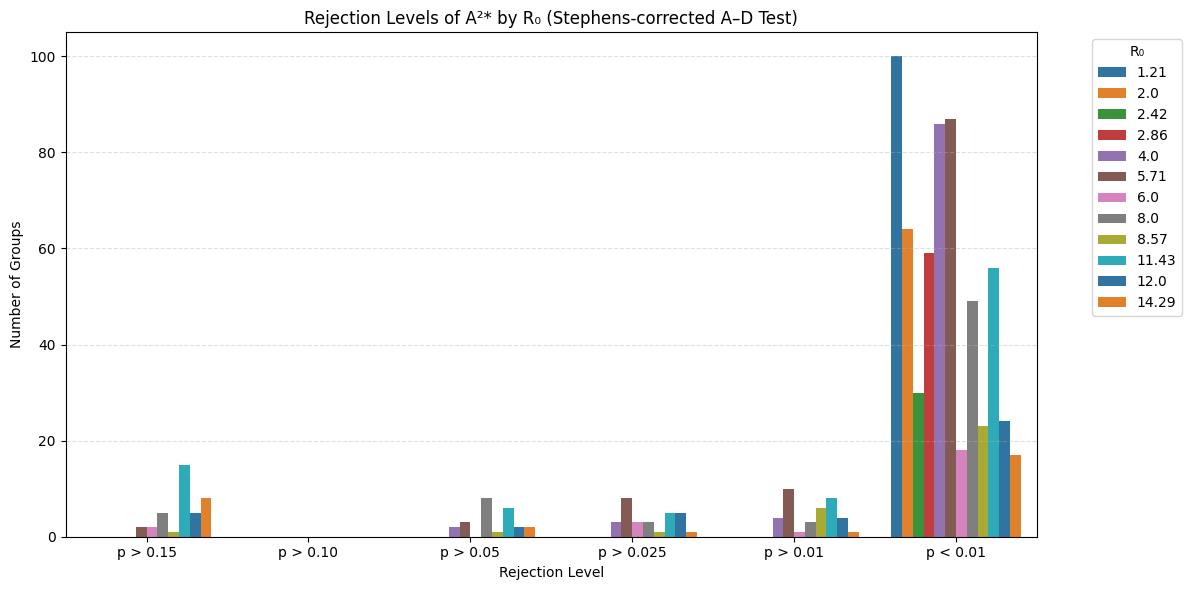

In [30]:
# Optional: round R₀ values for cleaner grouping
ad_df["R0_rounded"] = ad_df["R0"].round(2)

# Make sure rejection_level is ordered
rejection_order = ["p > 0.15", "p > 0.10", "p > 0.05", "p > 0.025", "p > 0.01", "p < 0.01"]
ad_df["rejection_level"] = pd.Categorical(ad_df["rejection_level"], categories=rejection_order, ordered=True)

plt.figure(figsize=(12, 6))
sns.countplot(data=ad_df, x="rejection_level", hue="R0_rounded", palette="tab10")
plt.title("Rejection Levels of A²* by R₀ (Stephens-corrected A–D Test)")
plt.xlabel("Rejection Level")
plt.ylabel("Number of Groups")
plt.legend(title="R₀", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, axis='y', linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


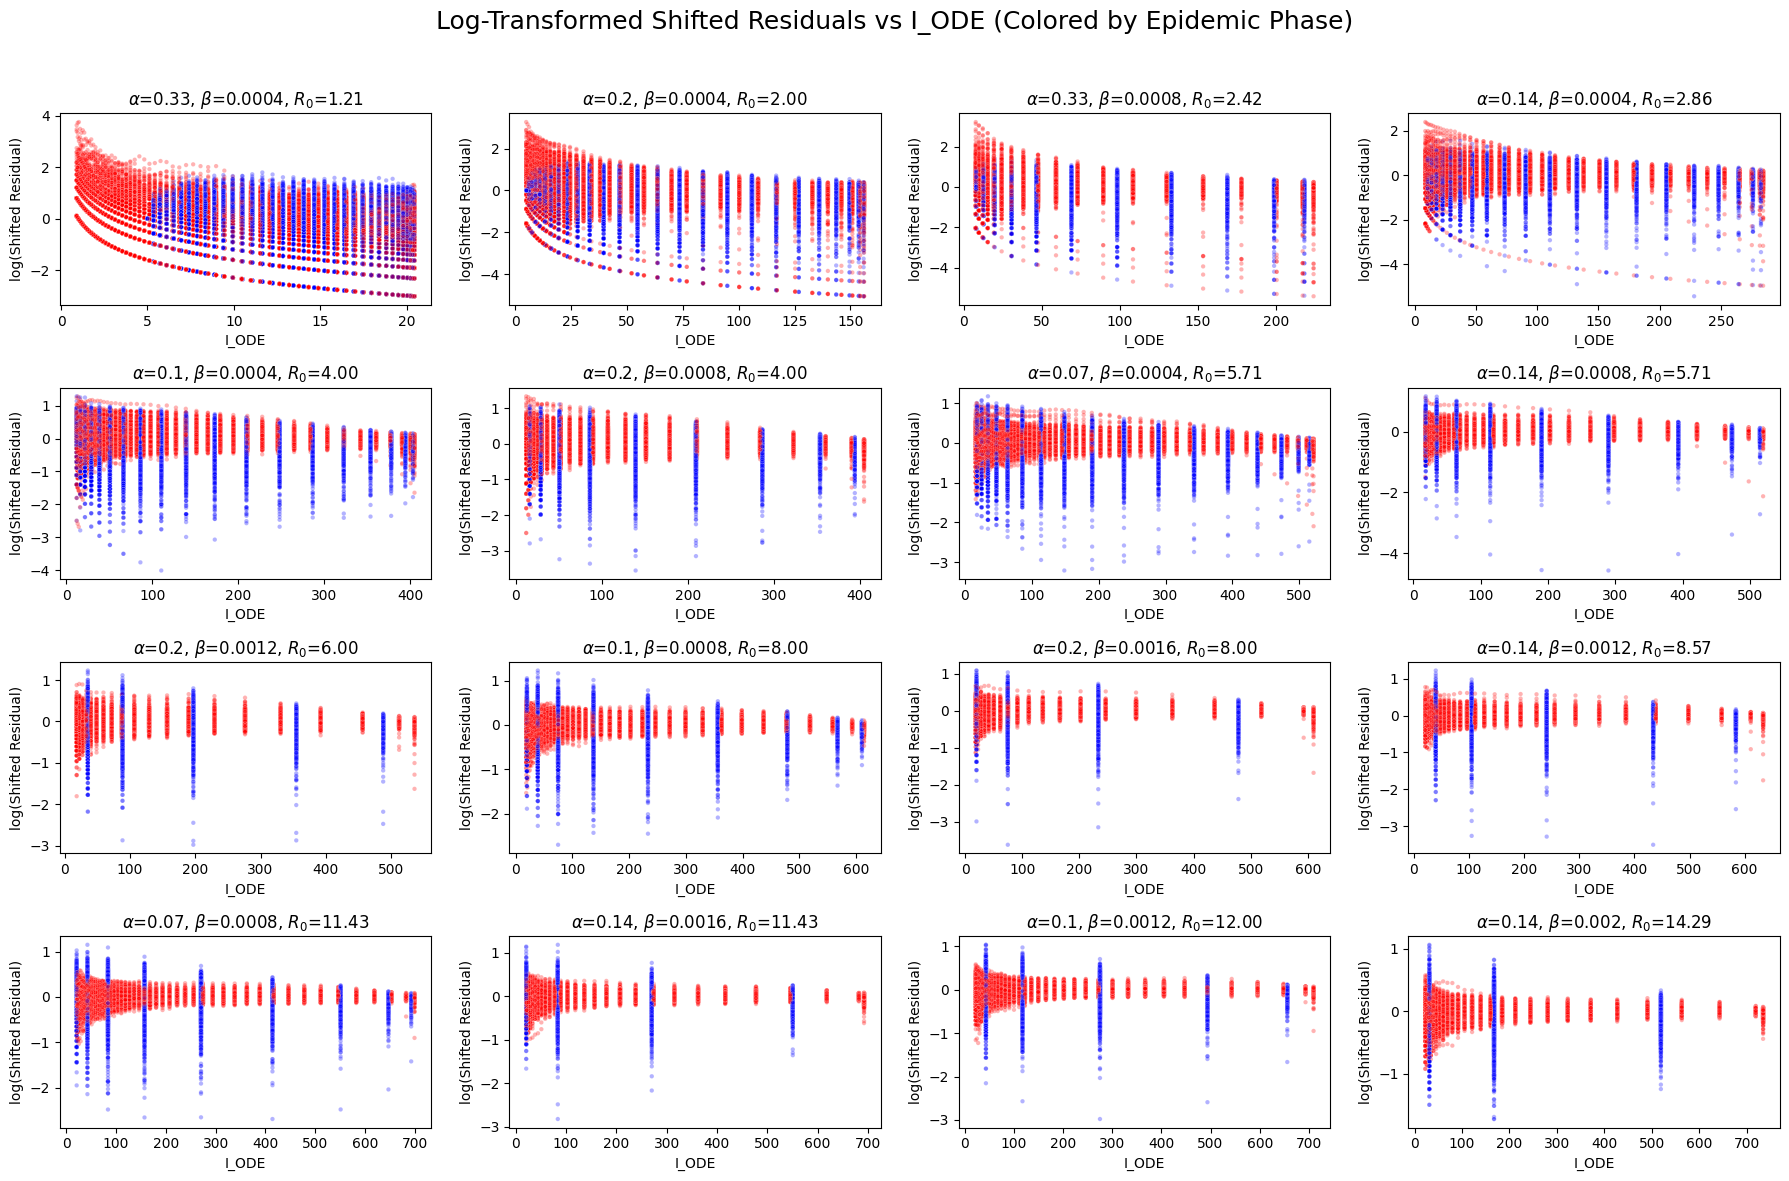

In [31]:
# Create a new column for the log-transformed residuals
residuals_df["log_residual_shifted"] = np.log(residuals_df["residual_shifted"])

# Setup subplot grid
num_plots = len(params_df)
num_cols = 4
num_rows = int(np.ceil(num_plots / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 12))
axes = axes.flatten()

# Plot log-transformed shifted residuals vs I_ODE
for idx, row in params_df.iterrows():
    alpha, beta, R0 = row["Alpha"], row["Beta"], row["R0"]
    ax = axes[idx]

    subset = residuals_df[(residuals_df["alpha"] == alpha) & (residuals_df["beta"] == beta)]

    sns.scatterplot(
        data=subset,
        x="I_ODE", y="log_residual_shifted", hue="phase",
        palette={"Before Peak": "blue", "After Peak": "red"},
        alpha=0.3, s=10, ax=ax, legend=False
    )

    ax.set_title(f"$\\alpha$={alpha}, $\\beta$={beta}, $R_0$={R0:.2f}")
    ax.set_xlabel("I_ODE")
    ax.set_ylabel("log(Shifted Residual)")

# Clean up unused axes
for j in range(idx + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Log-Transformed Shifted Residuals vs I_ODE (Colored by Epidemic Phase)", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


In [32]:
from scipy.stats import weibull_min
import numpy as np

# Stephens (1974) critical values for Weibull (shape & scale estimated, loc = 0)
weibull_crit_vals = {
    0.15: 0.637,
    0.10: 0.757,
    0.05: 0.918,
    0.025: 1.092,
    0.01: 1.321
}

# Function to compute raw A–D statistic for Weibull-min
def compute_ad_stat_weibull(data):
    n = len(data)
    sorted_data = np.sort(data)

    # Fit Weibull_min with fixed loc = 0
    c, loc, scale = weibull_min.fit(sorted_data, floc=0)
    cdf_vals = weibull_min.cdf(sorted_data, c, loc=loc, scale=scale)

    # Compute A–D statistic
    i = np.arange(1, n + 1)
    A2 = -n - np.sum((2*i - 1)/n * (np.log(cdf_vals) + np.log(1 - cdf_vals[::-1])))
    return A2


In [33]:
# Store results
ad_weibull_results = []

for (alpha, beta, R0, phase, I_val), group in tqdm(grouped, desc="Weibull A–D test"):
    data = group["residual_shifted"].values  # or log-transformed if preferred

    if len(data) >= 8:
        A2 = compute_ad_stat_weibull(data)

        # Determine rejection level
        for level, crit in sorted(weibull_crit_vals.items()):
            if A2 <= crit:
                rejected_at = f"p > {level}"
                break
        else:
            rejected_at = "p < 0.01"

        ad_weibull_results.append({
            "alpha": alpha,
            "beta": beta,
            "R0": R0,
            "phase": phase,
            "I_ODE": I_val,
            "n_obs": len(data),
            "A2_weibull": A2,
            "rejection_level_weibull": rejected_at
        })

# Convert to DataFrame
ad_weibull_df = pd.DataFrame(ad_weibull_results)


Weibull A–D test:   0%|          | 0/752 [00:00<?, ?it/s]

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/tmp/ipykernel_21/2299901667.py:24: RuntimeWarning: divide by zero encountered in log
  A2 = -n - np.sum((2*i - 1)/n * (np.log(cdf_vals) + np.log(1 - cdf_vals[::-1])))
Weibull A–D test:   3%|▎         | 26/752 [00:00<00:02, 250.82it/s]

Weibull A–D test:   7%|▋         | 53/752 [00:00<00:02, 253.55it/s]

Weibull A–D test:  12%|█▏        | 88/752 [00:00<00:02, 295.84it/s]

Weibull A–D test:  16%|█▌        | 118/752 [00:00<00:02, 270.05it/s]

Weibull A–D test:  20%|█▉        | 150/752 [00:00<00:02, 286.28it/s]

... (14 outputs left out)

Weibull A–D test:  82%|████████▏ | 616/752 [00:02<00:00, 308.31it/s]

Weibull A–D test:  89%|████████▉ | 670/752 [00:02<00:00, 373.26it/s]

Weibull A–D test:  95%|█████████▌| 716/752 [00:02<00:00, 397.19it/s]

Weibull A–D test: 100%|██████████| 752/752 [00:02<00:00, 321.49it/s]

<Axes: xlabel='rejection_level_weibull', ylabel='count'>

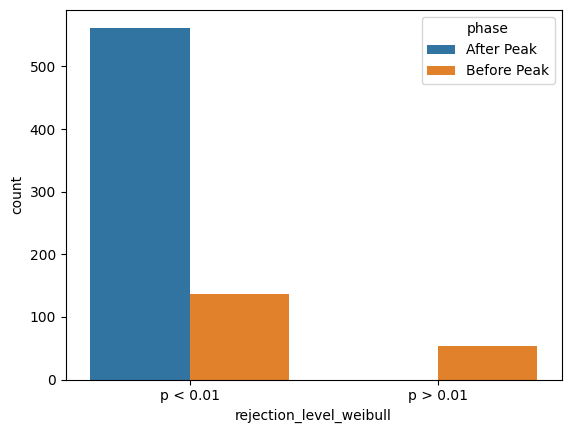

In [34]:
sns.countplot(data=ad_weibull_df, x="rejection_level_weibull", hue="phase")


In [35]:
from statsmodels.stats.diagnostic import lilliefors
import numpy as np
import pandas as pd
from tqdm import tqdm

# Store results
lillie_results = []

for (alpha, beta, R0, phase, I_val), group in tqdm(grouped, desc="Lilliefors test (log residuals)"):
    data = group["residual_shifted"].values
    if len(data) >= 8:
        log_data = np.log(data)
        stat, p_val = lilliefors(log_data)
        lillie_results.append({
            "alpha": alpha,
            "beta": beta,
            "R0": R0,
            "phase": phase,
            "I_ODE": I_val,
            "n_obs": len(log_data),
            "D_stat": stat,
            "p_value": p_val
        })

lillie_df = pd.DataFrame(lillie_results)


Lilliefors test (log residuals):   0%|          | 0/752 [00:00<?, ?it/s]

Lilliefors test (log residuals):  62%|██████▏   | 466/752 [00:00<00:00, 4651.44it/s]

/sessions/rcw-01yv5fv25e9u8aga9kyfzybb/.local/lib/python3.10/site-packages/statsmodels/stats/_lilliefors.py:304: RuntimeWarning: invalid value encountered in divide
  z = (x - x.mean()) / x.std(ddof=1)


Lilliefors test (log residuals): 100%|██████████| 752/752 [00:00<00:00, 5122.73it/s]

In [36]:
lillie_df

,alpha,beta,R0,phase,I_ODE,n_obs,D_stat,p_value
0,0.07,0.0004,5.71,After Peak,16.49,1000,0.073170,0.001
1,0.07,0.0004,5.71,After Peak,17.65,1000,0.076133,0.001
2,0.07,0.0004,5.71,After Peak,18.89,1000,0.065632,0.001
3,0.07,0.0004,5.71,After Peak,20.22,1000,0.060237,0.001
4,0.07,0.0004,5.71,After Peak,21.65,1000,0.054053,0.001
...,...,...,...,...,...,...,...,...
747,0.33,0.0008,2.42,Before Peak,98.27,991,0.132460,0.001
748,0.33,0.0008,2.42,Before Peak,133.02,990,0.151154,0.001
749,0.33,0.0008,2.42,Before Peak,168.82,990,0.170172,0.001
750,0.33,0.0008,2.42,Before Peak,198.86,990,0.200809,0.001


In [37]:
# Create categories for comparison
def categorize_lillie_p(p):
    if p < 0.01:
        return "p < 0.01"
    elif p < 0.025:
        return "p < 0.025"
    elif p < 0.05:
        return "p < 0.05"
    elif p < 0.10:
        return "p < 0.10"
    else:
        return "p ≥ 0.10"

lillie_df["rejection_level"] = lillie_df["p_value"].apply(categorize_lillie_p)


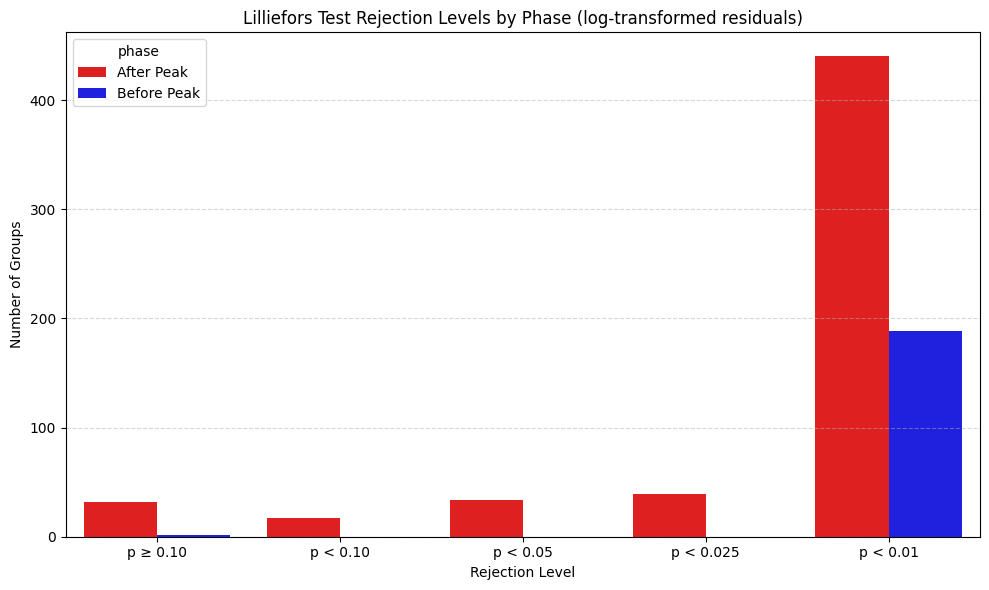

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ensure order of categories
rejection_order = ["p ≥ 0.10", "p < 0.10", "p < 0.05", "p < 0.025", "p < 0.01"]
lillie_df["rejection_level"] = pd.Categorical(lillie_df["rejection_level"], categories=rejection_order, ordered=True)

plt.figure(figsize=(10, 6))
sns.countplot(data=lillie_df, x="rejection_level", hue="phase", palette={"Before Peak": "blue", "After Peak": "red"})
plt.title("Lilliefors Test Rejection Levels by Phase (log-transformed residuals)")
plt.xlabel("Rejection Level")
plt.ylabel("Number of Groups")
plt.grid(True, axis='y', linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
